# 08 — The full model: `GPTLanguageModel`

**Chapter 2** · suggested time: 25 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/08_gpt_language_model.ipynb)

![Roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

All the pieces are ready. What remains is to **assemble** them and add the last one: the **position embedding**. This notebook shows the full code of the mini-GPT, runs it **without training it**, and checks its essential properties.

**By the end of this notebook you will be able to:**
1. read `GPTLanguageModel` from top to bottom and give the shape of each tensor;
2. explain why we **add** a position embedding;
3. check that the full model is **causal**;
4. explain `generate` (`block_size` window, last position, sampling).

In [1]:
# On Google Colab: fetch the course repo (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the minigpt.py file, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

text, tok, train_data, val_data = minigpt.prepare_data("shakespeare")
V = tok.vocab_size

PyTorch 2.15.0+cu132 | device: cpu


## 1. Why a position embedding?

Recall notebook 05: attention works on a **set** of vectors. Nothing in $QK^\top$ says who comes before whom (the mask only says *who is allowed to read whom*). Yet order matters enormously: `"dog"` ≠ `"god"`.

**Solution (GPT-2):** a second learned table, `nn.Embedding(block_size, C)`, which maps each **position** `0, 1, …, T−1` to a vector. We **add** it to the character embedding:

$$x_t = \underbrace{E_{\text{token}}[\text{idx}_t]}_{\text{which character?}} + \underbrace{E_{\text{pos}}[t]}_{\text{where?}}$$

The same `e` thus gets a different representation at position 0 and at position 5. Tokens have shape `(B, T, C)`, positions `(T, C)`: PyTorch adds **the same position table to each of the `B` examples** (*broadcasting*).

> The original Transformer used **fixed** sinusoids instead of a learned table; recent models often use RoPE (rotations). The idea stays the same: inject the order.

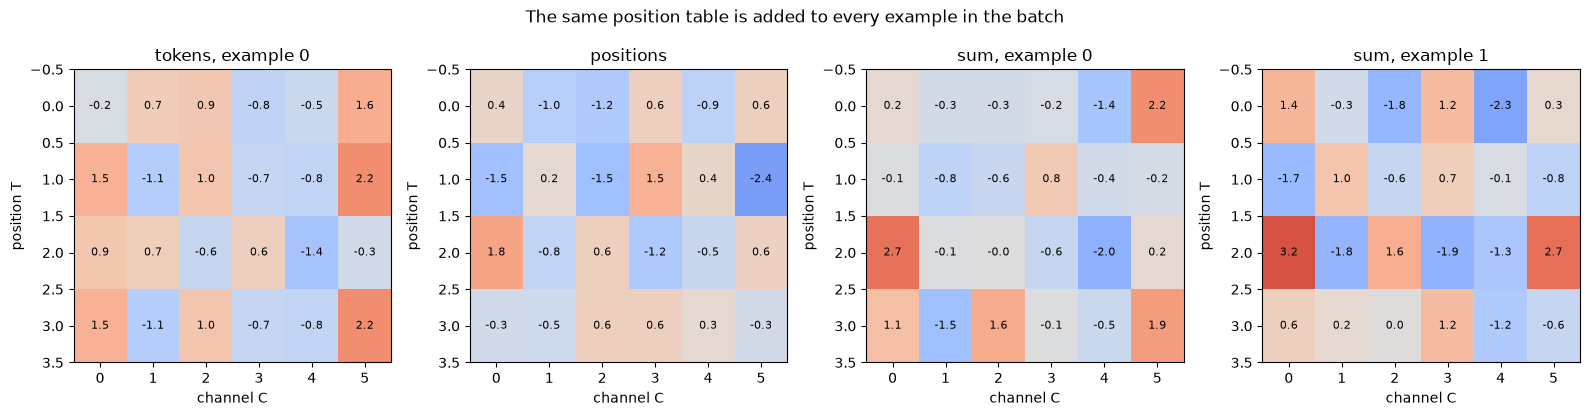

Token 1 is at positions 1 and 3 in example 0:
  same token embedding? True
  same final vector?    False


In [3]:
B_vis, T_vis, C_vis = 2, 4, 6
indices = torch.tensor([[0, 1, 2, 1], [2, 0, 1, 2]])
gen = torch.Generator().manual_seed(2026)
token_table = torch.randn(3, C_vis, generator=gen)
position_table = torch.randn(T_vis, C_vis, generator=gen)
tok_emb = token_table[indices]           # (2, 4, 6)
x_demo = tok_emb + position_table        # (2, 4, 6) + (4, 6) -> (2, 4, 6)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, M, title in [(axes[0], tok_emb[0], "tokens, example 0"), (axes[1], position_table, "positions"),
                     (axes[2], x_demo[0], "sum, example 0"), (axes[3], x_demo[1], "sum, example 1")]:
    ax.imshow(M, cmap="coolwarm", vmin=-4, vmax=4, aspect="auto")
    for i in range(T_vis):
        for j in range(C_vis):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel("channel C"); ax.set_ylabel("position T")
fig.suptitle("The same position table is added to every example in the batch"); fig.tight_layout(); plt.show()
print("Token 1 is at positions 1 and 3 in example 0:")
print("  same token embedding?", torch.equal(tok_emb[0, 1], tok_emb[0, 3]))
print("  same final vector?   ", torch.equal(x_demo[0, 1], x_demo[0, 3]))

## 2. The full code

![The mini-GPT](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/04_decoder_only.png)

Here is **the whole** model, in the order we built it. It is exactly the code in `minigpt.py`.

| Class | Role | Notebook |
|---|---|---|
| `Head` | one causal attention head | 05 |
| `MultiHeadAttention` | `n_head` heads + projection | 05 |
| `FeedForward` | `C → 4C → ReLU → C` + dropout | 06 |
| `Block` | LN → attention → `+`, LN → FeedForward → `+` | 07 |
| `GPTLanguageModel` | embeddings → blocks → LN → `lm_head`; loss; `generate` | here |

In [4]:
class Head(nn.Module):
    """One causal self-attention head."""

    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)    # "what I contain"
        self.query = nn.Linear(n_embd, head_size, bias=False)  # "what I am looking for"
        self.value = nn.Linear(n_embd, head_size, bias=False)  # "what I pass on"
        # The mask is NOT a parameter: register_buffer stores it with the model
        # (and moves it to the GPU with it) without the optimizer touching it.
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                          # (B, T, hs)
        q = self.query(x)                                        # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5      # (B, T, T) scores
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))  # forbid the future
        wei = F.softmax(wei, dim=-1)                             # each row sums to 1
        wei = self.dropout(wei)
        v = self.value(x)                                        # (B, T, hs)
        return wei @ v                                           # (B, T, hs)


class MultiHeadAttention(nn.Module):
    """Several heads in parallel, concatenated then projected back to n_embd channels."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.heads = nn.ModuleList(
            [Head(n_embd, head_size, block_size, dropout) for _ in range(n_head)]
        )
        self.proj = nn.Linear(n_head * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)    # (B, T, n_head*hs)
        return self.dropout(self.proj(out))                     # (B, T, n_embd)


class FeedForward(nn.Module):
    """Small network applied independently at each position: C -> 4C -> ReLU -> C."""

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Transformer block (pre-norm): communication (attention) then computation (FeedForward)."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # residual connection #1
        x = x + self.ffwd(self.ln2(x))   # residual connection #2
        return x


class GPTLanguageModel(nn.Module):
    """Character-level, decoder-only mini-GPT."""

    def __init__(self, vocab_size, block_size=64, n_embd=64, n_head=4, n_layer=4, dropout=0.2):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)]
        )
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)                                    # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb                    # (B, T, C)  broadcast over B
        x = self.blocks(x)                       # (B, T, C)
        x = self.ln_f(x)                         # (B, T, C)
        logits = self.lm_head(x)                 # (B, T, V)

        loss = None
        if targets is not None:
            B, T, V = logits.shape
            loss = F.cross_entropy(logits.view(B * T, V), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]          # at most block_size characters
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature       # last position only
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

### Reading `forward` line by line

| Line | Shape | Comment |
|---|---|---|
| `idx` | `(B, T)` | character indices |
| `tok_emb` | `(B, T, C)` | *which* character |
| `pos_emb` | `(T, C)` | *where*: positions `0 … T−1` |
| `x = tok_emb + pos_emb` | `(B, T, C)` | input of the residual stream |
| `self.blocks(x)` | `(B, T, C)` | `n_layer` × (communication + computation) |
| `self.ln_f(x)` | `(B, T, C)` | final normalization |
| `self.lm_head(x)` | `(B, T, V)` | one score per possible character, at each position |
| `F.cross_entropy(...)` | scalar | the `(B·T, V)` reshape from notebook 03 |

**Difference from the bigram:** the bigram's `(V, V)` table jumped directly from the index to the logits. Here, the `(V, C)` table only gives a **representation**; the blocks build the prediction by looking at the context, and `lm_head` translates it into `V` scores.

## 3. Instantiating the model

In [5]:
config = dict(block_size=64, n_embd=64, n_head=4, n_layer=4, dropout=0.2)
torch.manual_seed(1337)
model = GPTLanguageModel(V, **config).to(device)
print(model)
print(f"\ntrainable parameters: {sum(p.numel() for p in model.parameters()):,}")
print("buffers (not trainable):", [n for n, _ in model.named_buffers()][:2], "...")

GPTLanguageModel(
  (token_embedding_table): Embedding(65, 64)
  (position_embedding_table): Embedding(64, 64)
  (blocks): Sequential(
    (0): Block(
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (sa): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=64, out_features=16, bias=False)
            (query): Linear(in_features=64, out_features=16, bias=False)
            (value): Linear(in_features=64, out_features=16, bias=False)
            (dropout): Dropout(p=0.2, inplace=False)
          )
        )
        (proj): Linear(in_features=64, out_features=64, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
      )
      (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=64, out_features=256, bias=True)
          (1): ReLU()
          (2): Linear(in_features=256, out_featu

## 4. A *forward* pass on a real batch

In [6]:
xb, yb = minigpt.get_batch(train_data, batch_size=8, block_size=config["block_size"], device=device)
logits, loss = model(xb, yb)
print("idx   :", tuple(xb.shape))
print("logits:", tuple(logits.shape), "= (B, T, V)")
print(f"loss  : {loss.item():.3f}   (uniform baseline log V = {math.log(V):.3f})")

idx   : (8, 64)
logits: (8, 64, 65) = (B, T, V)
loss  : 4.352   (uniform baseline log V = 4.174)


The initial loss is **close to `log V`**: the untrained model is almost uniform (this was not the case for the bigram, whose `N(0,1)` table directly gave noisy logits; here the logits go through a LayerNorm and an `nn.Linear` whose initialization is small).

## 5. Checking that the full model is causal

A simple, decisive test: if we change the character at position `t`, the logits at positions **before** `t` must not move. (We switch to `model.eval()` to turn off dropout, otherwise two passes would differ anyway.)

In [7]:
model.eval()
x1 = xb[:1].clone()
x2 = x1.clone(); x2[0, 40] = (x2[0, 40] + 1) % V          # we change ONLY position 40
l1, _ = model(x1); l2, _ = model(x2)
diff = (l1 - l2).abs().amax(-1)[0]
print("positions whose logits changed:", [t for t in range(diff.shape[0]) if diff[t] > 1e-5])
assert diff[:40].max() < 1e-5, "information leak from the future!"
print("Positions 0 to 39 untouched: the full model is causal.")
model.train();

positions whose logits changed: [40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]
Positions 0 to 39 untouched: the full model is causal.


## 6. Generating (without training)

`generate` repeats:
1. **crop** the context to the last `block_size` characters: the position embedding only has `block_size` rows, and so does the `tril` mask;
2. compute the logits and keep only the **last position**;
3. softmax → `torch.multinomial` → append the sampled character to the context.

What happens if we forget step 1?

In [8]:
too_long = torch.zeros((1, config["block_size"] + 1), dtype=torch.long, device=device)
try:
    model(too_long)
except Exception as e:
    print("Without cropping:", type(e).__name__, "-", str(e)[:90])

model.eval()
torch.manual_seed(0)
start = torch.full((1, 1), tok.stoi["\n"], dtype=torch.long, device=device)
print("\nText generated by the UNTRAINED model:\n")
print(tok.decode(model.generate(start, max_new_tokens=120)[0]))
model.train();

Without cropping: IndexError - index out of range in self

Text generated by the UNTRAINED model:




t3ZrjmhkkqkARxLsX?tfWHoHKu !eTHjfU&&NdkIgLlsvSBUMHcoRD$BygXOPnt;
kurM h&?j D?R!sORHWvC!BsH3snhPRjs?Ma-s3KyporWwXjMw
JIRc


Noise, as expected: the model is ready, but does not know anything yet. That is what notebook 09 is about.

> **Technical note:** `generate` recomputes **the whole** context for each new character. Real models keep the already computed keys and values in memory (*KV cache*) so they only compute the new position.

## Summary

- `GPTLanguageModel` = embeddings (token **+** position) → `n_layer` blocks → LayerNorm → `lm_head`.
- The position embedding gives attention the notion of **order**; it limits the context to `block_size`.
- Constant shape `(B, T, C)` at the core of the network; `(B, T, V)` at the output.
- The full model is **causal**: a character can only influence the positions that follow it.
- `generate`: crop, take the last position, sample, repeat.

**Check your understanding**
1. What does row `t` of `position_embedding_table` contain? Is it the same for every example in the batch?
2. Why must `generate` crop the context to `block_size`?
3. How many parameters would you need to add to go from `block_size = 64` to `256` with `C = 64`?

**Next → 09:** training, curves, evaluation and generation.

### References
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) and his code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) ("positional encoding" and "full finished code" parts).
- A. Karpathy, [nanoGPT](https://github.com/karpathy/nanoGPT) — the "serious" version of this code (reproduces GPT-2).
- Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), NeurIPS 2017 — §3.5 *Positional Encoding*.
- J. Su et al., [*RoFormer: Enhanced Transformer with Rotary Position Embedding*](https://arxiv.org/abs/2104.09864), 2021 — RoPE.